# Amazon Bedrock curso - RAG

Anotações do curso de Amazon Bedrock sobre **RAG (Retrieval-Augmented Generation)**: o que são embeddings, como funciona a busca por similaridade, como criar uma base de conhecimento (Knowledge Base) na AWS e como fazer o modelo responder perguntas usando o conteúdo de um PDF.

## Sumário

1. [Configuração do ambiente](#1.-Configuração-do-ambiente)
2. [Embeddings na prática](#2.-Embeddings-na-prática)
3. [Busca vetorial](#3.-Busca-vetorial)
4. [Base de conhecimento na AWS](#4.-Base-de-conhecimento-na-AWS)
5. [Conectando à base de conhecimento](#5.-Conectando-à-base-de-conhecimento)
6. [RAG em duas etapas: busca + geração](#6.-RAG-em-duas-etapas:-busca-+-geração)
7. [Citações: de onde veio a resposta](#7.-Citações:-de-onde-veio-a-resposta)
8. [Chatbot interativo](#8.-Chatbot-interativo)
9. [Analisando o score da busca](#9.-Analisando-o-score-da-busca)
10. [Resumo dos aprendizados](#10.-Resumo-dos-aprendizados)
11. [Encerrando o curso: desligando os recursos na AWS](#11.-Encerrando-o-curso:-desligando-os-recursos-na-AWS)

---
## 1. Configuração do ambiente

O nosso objetivo agora é fazer a conexão desse arquivo com a AWS, utilizando as chaves criadas anteriormente, e depois fazer as chamadas aos modelos.

Isso é feito utilizando uma biblioteca chamada **Boto3**: é ela que faz a conexão da nossa aplicação em Python com a AWS.

In [ ]:
# Instalando o Boto3, biblioteca que faz a conexão da nossa aplicação em Python com a AWS.
# O %pip instala no mesmo ambiente do kernel do notebook (mais seguro que !pip).
%pip install boto3

### 1.1 Credenciais da AWS

> ⚠️ **Boa prática de segurança:** nunca escreva a `aws_access_key_id` e a `aws_secret_access_key` direto no código. Qualquer pessoa que tiver acesso ao notebook (GitHub, e-mail, print de tela) passa a ter acesso à sua conta da AWS — e às cobranças.

Por isso as chaves são lidas do arquivo `curso_bedrock_accessKeys.csv` (baixado no console do IAM ao criar a chave), que fica fora do código. Criamos **uma única sessão** (`boto3.Session`) com essas credenciais e a região, e todos os clientes (`bedrock`, `bedrock-runtime` e `bedrock-agent-runtime`) saem dela — assim a configuração fica em um só lugar.

Alternativa ainda melhor: rodar `aws configure` no terminal uma vez. Aí basta `boto3.Session(region_name="us-east-1")`, sem informar chave nenhuma.

Nesta mesma célula já importamos as bibliotecas usadas ao longo do notebook:

| Biblioteca | Para que usamos |
| --- | --- |
| `json` | montar a requisição e ler a resposta do modelo de embedding |
| `numpy` | organizar os vetores em uma matriz |
| `matplotlib` | desenhar o gráfico dos embeddings |
| `sklearn` (`PCA`) | reduzir os vetores para 2 dimensões e conseguir plotar |

In [1]:
# Importando a biblioteca boto3 para interagir com os serviços da AWS
import csv
import boto3
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Lendo as credenciais do arquivo CSV gerado pelo IAM (fora do código)
with open("curso_bedrock_accessKeys.csv", encoding="utf-8-sig") as f:
    credenciais = next(csv.DictReader(f))

# Sessão única: todos os serviços da AWS são criados a partir dela
session = boto3.Session(
    aws_access_key_id=credenciais["Access key ID"],
    aws_secret_access_key=credenciais["Secret access key"],
    region_name="us-east-1",
)

---
## 2. Embeddings na prática

Antes de montar o RAG, precisamos entender a peça central dele: o **embedding**.

Um embedding é a transformação de um texto em um **vetor de números** que representa o seu *significado*. Textos com sentidos parecidos geram vetores próximos, mesmo que usem palavras diferentes. É isso que permite buscar "por significado", e não só por palavra-chave.

| Termo | O que é |
| --- | --- |
| **Embedding** | Vetor numérico que representa o significado de um texto. |
| **Dimensão** | Quantidade de números do vetor. O Titan Text Embeddings V2 gera **1024**. |
| **Similaridade** | O quanto dois vetores "apontam na mesma direção". Quanto mais perto de 1, mais parecidos são os textos. |

### 2.1 Cliente `bedrock-runtime`

O modelo de embedding é executado pelo mesmo cliente que executa os modelos de texto: o **`bedrock-runtime`**.

In [8]:
# Configurando o cliente do Amazon Bedrock Runtime: é ele que efetivamente executa os modelos.
bedrock_runtime = session.client(service_name='bedrock-runtime')

### 2.2 Função para gerar embeddings

Vamos usar o modelo **`amazon.titan-embed-text-v2:0`** (Amazon Titan Text Embeddings V2): ele recebe um texto e devolve um vetor.

- **Ida:** o corpo da requisição é `{"inputText": texto}`, o formato nativo do Titan. Por isso usamos o `invoke_model` e convertemos o dicionário com `json.dumps`.
- **Volta:** o `invoke_model` devolve um *stream*. Lemos os bytes com `.read()`, convertemos com `json.loads` e pegamos a chave `["embedding"]`.

In [10]:
# Criando a função para a geração dos embeddings
def generate_embedding(text):
    body = json.dumps({
        "inputText": text
    })

    response = bedrock_runtime.invoke_model(
        modelId="amazon.titan-embed-text-v2:0",
        body = body,
        contentType = "application/json",
        accept = "application/json"
    )

    result = json.loads(response["body"].read())

    return result["embedding"]

### 2.3 Gerando embeddings de frases

Criamos 8 frases curtas sobre o conteúdo do PDF da IA Expert Academy: duas sobre **planos**, e as demais sobre **Machine Learning**, **Deep Learning**, **projetos** e **agentes**. A ideia é ver se o modelo agrupa as frases pelo assunto.

In [11]:
# Criando uma lista com algumas frases presentes no PDF
texts = [
    "O plano mensal custa R$24,90." ,
    "O plano anual oferece economia para o aluno." ,
    "Machine Learning permite criar modelos preditivos." ,
    "Deep Learning utiliza redes neurais artificiais." ,
    "Projetos práticos ajudam na construção de portfólio." ,
    "Agentes de IA podem automatizar tarefas." ,
    "IA trilha de Machine Learning possui vários cursos." ,
    "A trilha de Deep Learning aborda redes neurais."
]

Agora geramos um embedding para cada frase.

> ⚠️ Cada frase é uma chamada ao modelo. O custo de embeddings é baixo, mas é cobrado.

In [15]:
# Vamos criar uma lista com os embeddings
embeddings = []
for text in texts:
    embedding = generate_embedding(text)
    embeddings.append(embedding)
    print("-" * 50)
    print(text)
    print(f"Tamanho do vetor: {len(embedding)}")

--------------------------------------------------
O plano mensal custa R$24,90.
Tamanho do vetor: 1024
--------------------------------------------------
O plano anual oferece economia para o aluno.
Tamanho do vetor: 1024
--------------------------------------------------
Machine Learning permite criar modelos preditivos.
Tamanho do vetor: 1024
--------------------------------------------------
Deep Learning utiliza redes neurais artificiais.
Tamanho do vetor: 1024
--------------------------------------------------
Projetos práticos ajudam na construção de portfólio.
Tamanho do vetor: 1024
--------------------------------------------------
Agentes de IA podem automatizar tarefas.
Tamanho do vetor: 1024
--------------------------------------------------
IA trilha de Machine Learning possui vários cursos.
Tamanho do vetor: 1024
--------------------------------------------------
A trilha de Deep Learning aborda redes neurais.
Tamanho do vetor: 1024


✅ Todas as frases viraram vetores de **1024 números**, independentemente do tamanho do texto.

### 2.4 Organizando os vetores com NumPy

Os embeddings estão guardados em uma lista Python comum:

In [16]:
# Os dados estão no formato de lista
type(embeddings)

list

Para manipular com mais facilidade, convertemos a lista em um **array NumPy** (uma matriz).

In [17]:
# Convertendo a lista de embeddings em um array NumPy
embeddings_array = np.array(embeddings)
embeddings_array.shape

(8, 1024)

O formato `(8, 1024)` significa **8 linhas** (uma por frase) e **1024 colunas** (as dimensões de cada vetor).

In [18]:
# Visualizando o conteúdo do array
embeddings_array

array([[-1.22657642e-01,  4.47485074e-02,  3.63533311e-02, ...,
        -1.22188935e-02,  1.28062656e-02,  2.50528529e-02],
       [-7.79144987e-02,  1.48503613e-02,  1.35168675e-02, ...,
         1.09101487e-02,  1.59150269e-02, -1.90588403e-02],
       [-3.70531902e-02,  7.35805407e-02,  1.04012182e-02, ...,
         2.07237285e-02, -2.01401152e-02, -6.09193882e-03],
       ...,
       [-5.70918545e-02,  5.82243269e-03, -2.11251061e-02, ...,
         5.66042727e-05, -3.58753977e-03, -3.80620807e-02],
       [-3.93722840e-02,  4.78317142e-02,  2.73954645e-02, ...,
         2.59775072e-02, -2.12069601e-02, -5.90515882e-03],
       [-4.34926189e-02,  5.71304150e-02,  3.55698913e-02, ...,
         1.30553925e-02, -1.93897989e-02, -3.47088533e-03]],
      shape=(8, 1024))

Cada linha é uma frase representada em números. Sozinhos, esses valores não dizem nada para nós: o significado está na **posição relativa** entre os vetores. Abaixo, o vetor da primeira frase:

In [19]:
# Visualizando o vetor da primeira frase
embeddings_array[0]

array([-0.12265764,  0.04474851,  0.03635333, ..., -0.01221889,
        0.01280627,  0.02505285], shape=(1024,))

### 2.5 Visualizando os embeddings com PCA

Não dá para desenhar 1024 dimensões. O **PCA** (Análise de Componentes Principais) reduz os vetores para **2 dimensões**, mantendo o máximo possível da variação entre eles. Assim conseguimos colocar cada frase como um ponto em um gráfico.

In [20]:
# Agora vamos usar a técnica PCA para visualizar o resultado bi-dimensional
pca = PCA(n_components=2)
reduce_vectors = pca.fit_transform(embeddings_array)
reduce_vectors

array([[ 0.54761782,  0.32806245],
       [ 0.53670812,  0.25973194],
       [-0.29084126, -0.23125095],
       [-0.47695098,  0.39929026],
       [ 0.48776375, -0.21056074],
       [ 0.05191888, -0.52694972],
       [-0.31028126, -0.32169767],
       [-0.54593508,  0.30337443]])

As 1024 colunas foram reduzidas para 2. Cada linha agora é um par de coordenadas (x, y) que podemos plotar.

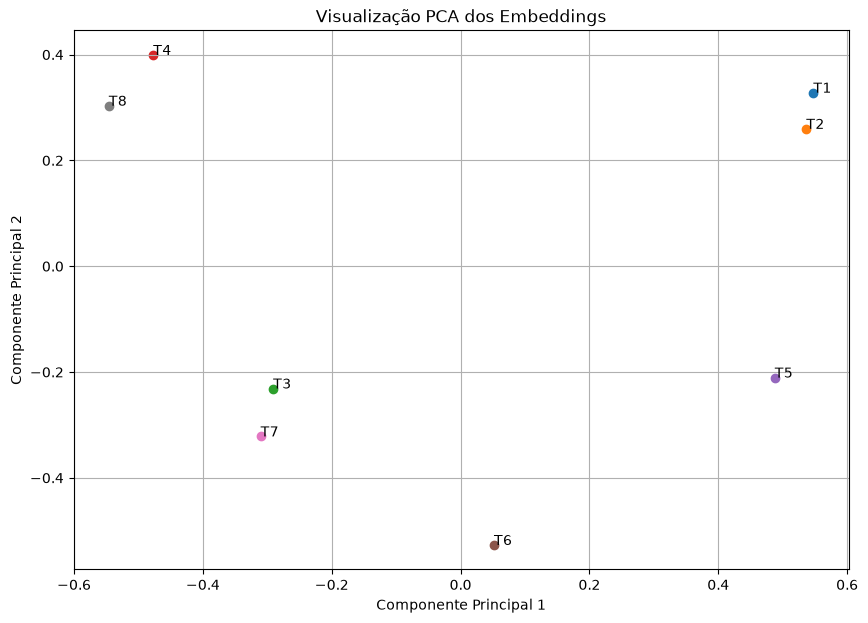


 Legenda:
T1: O plano mensal custa R$24,90.
T2: O plano anual oferece economia para o aluno.
T3: Machine Learning permite criar modelos preditivos.
T4: Deep Learning utiliza redes neurais artificiais.
T5: Projetos práticos ajudam na construção de portfólio.
T6: Agentes de IA podem automatizar tarefas.
T7: IA trilha de Machine Learning possui vários cursos.
T8: A trilha de Deep Learning aborda redes neurais.


In [ ]:
# Visualizando o resultado do PCA, para compreender como funciona o processo de embeddings
plt.figure(figsize=(10, 7))
for i, text in enumerate(texts):
    # print(f"Texto: {text} - Vetor PCA: {reduce_vectors[i]}")
    x = reduce_vectors[i, 0]
    y = reduce_vectors[i, 1]
    plt.scatter(x, y)

    plt.annotate(f"T{i+1}", (x,y))

plt.title("Visualização PCA dos Embeddings")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.grid(True)

plt.show()

print("\nLegenda:")
for i, text in enumerate(texts):
    print(f"T{i+1}: {text}")

**Como ler o gráfico:** frases com assuntos parecidos ficaram próximas.

| Grupo | Frases | Coordenadas |
| --- | --- | --- |
| Planos | T1 e T2 | (0,55; 0,33) e (0,54; 0,26) |
| Deep Learning | T4 e T8 | (-0,48; 0,40) e (-0,55; 0,30) |
| Machine Learning | T3 e T7 | (-0,29; -0,23) e (-0,31; -0,32) |

> 💡 O PCA descarta parte da informação para caber em 2 dimensões. Ele serve só para **visualizar**; a busca de verdade usa os 1024 números.

---
## 3. Busca vetorial

Com os embeddings prontos, vamos fazer a etapa de **recuperação** (*retrieval*) do RAG: dada uma pergunta, encontrar as frases mais relacionadas a ela.

1. Transformar a pergunta em embedding, **com o mesmo modelo** usado nas frases.
2. Comparar esse vetor com o de cada frase usando a **similaridade de cosseno**.
3. Ordenar da frase mais parecida para a menos parecida.

> ⚠️ Vetores de modelos de embedding diferentes não são comparáveis. Pergunta e documentos precisam usar o mesmo modelo.

### 3.1 Embedding da pergunta

In [25]:
from sklearn.metrics.pairwise import cosine_similarity

In [26]:
# Vamos criar a pergunta
query = "Como funciona o plano de assinatura"

In [27]:
# Agora vamos chamar o modelo de embedding para transformar a pergunta em um vetor (número)
query_embedding = generate_embedding(query)

A função `cosine_similarity` espera uma **matriz 2D** (linhas = textos). Como temos um único vetor, o `reshape(1, -1)` o transforma em 1 linha × 1024 colunas.

In [28]:
# Estamos convertendo o vetor de embedding da pergunta em um array numpy e ajustando sua forma para 2D
query_embedding = np.array(query_embedding).reshape(1, -1)

In [29]:
# Visualizando a forma do embedding da pergunta
query_embedding.shape

(1, 1024)

### 3.2 Calculando a similaridade

In [ ]:
# Calculando a similaridade entre o embedding da pergunta e os embeddings dos textos
similaridades = cosine_similarity(query_embedding, embeddings) [0] # Adicionamos [0] para ter um retorno de um vetor, antes era uma matriz 2D, agora é um vetor 1D
similaridades

array([0.23895247, 0.30682427, 0.11221589, 0.06385759, 0.14218831,
       0.08966234, 0.08694477, 0.0653064 ])

O resultado é um valor para cada frase, na mesma ordem da lista `texts`.

> 💡 Quanto mais próximo de 1, mais parecidas são as sentenças.

Para facilitar a leitura, juntamos cada frase com o seu score e ordenamos do maior para o menor:

In [33]:
# Juntando cada frase com o seu score e ordenando do mais parecido para o menos parecido
results = list(zip(texts, similaridades))
results = sorted(results, key=lambda x: x[1], reverse=True)
for text, score in results:
    print(f"{score: .4f} -> {text}")

 0.3068 -> O plano anual oferece economia para o aluno.
 0.2390 -> O plano mensal custa R$24,90.
 0.1422 -> Projetos práticos ajudam na construção de portfólio.
 0.1122 -> Machine Learning permite criar modelos preditivos.
 0.0897 -> Agentes de IA podem automatizar tarefas.
 0.0869 -> IA trilha de Machine Learning possui vários cursos.
 0.0653 -> A trilha de Deep Learning aborda redes neurais.
 0.0639 -> Deep Learning utiliza redes neurais artificiais.


✅ As duas frases sobre **planos** ficaram no topo, mesmo sem a pergunta conter as palavras "mensal", "anual" ou "custa". Isso é **busca por significado**.

No RAG, são esses trechos mais similares que vão ser enviados ao modelo como contexto para ele responder.

---
## 4. Base de conhecimento na AWS

Na prática não precisamos calcular embeddings e similaridade à mão: o Amazon Bedrock tem as **Knowledge Bases**, que fazem todo esse processo de forma gerenciada. A criação da base é feita no **console da AWS**, usando o PDF `IA Expert Academy.pdf` como fonte.

### 4.1 Fluxo do RAG

| Etapa | Componente | O que acontece |
| --- | --- | --- |
| 1 | **PDF** | Fonte de conhecimento (o documento de origem). |
| 2 | **Amazon S3** | Armazena o PDF com segurança e alta disponibilidade. |
| 3 | **Chunking** | O documento é dividido em pequenos trechos (*chunks*) para facilitar a indexação e a busca. |
| 4 | **Embeddings** | Cada chunk é convertido em um vetor que representa o significado do texto. |
| 5 | **Vector store** | Os vetores são armazenados em uma base vetorial para permitir buscas semânticas rápidas. |
| 6 | **Retrieval** | A pergunta do usuário vira vetor e é comparada com a base para encontrar os trechos mais relevantes. |
| 7 | **LLM (geração)** | Os trechos recuperados são enviados junto com a pergunta para o modelo gerar a resposta. |
| 8 | **Resposta** | A resposta gerada é exibida para o usuário. |

As etapas **2 a 5** acontecem quando a base é sincronizada (*sync* do data source). As etapas **6 a 8** acontecem a cada pergunta, e são elas que vamos fazer via código.

### 4.2 Tipos de Knowledge Base

O console oferece dois tipos de base, e isso muda o código:

| | **Bedrock Managed** | **Customer-managed** |
| --- | --- | --- |
| Banco vetorial | A AWS cuida de tudo (armazenamento, embeddings, reranking). | Você escolhe e mantém (OpenSearch, S3 Vectors...). |
| Configuração da busca | `managedSearchConfiguration` | `vectorSearchConfiguration` |
| `retrieve_and_generate` | ❌ Não suportado | ✅ Suportado |
| `retrieve` | ✅ Suportado | ✅ Suportado |

> ⚠️ A base usada neste notebook (`4SCLDZ9ZTH`) é do tipo **Bedrock Managed**, o padrão recomendado pelo console. Por isso o código das seções 6 e 9 é diferente do mostrado na aula, que usa `retrieve_and_generate` em uma base customer-managed.

### 4.3 Escolhendo o modelo de geração

Para a etapa de geração (etapa 7) precisamos de um modelo de texto. O primeiro passo é consultar o catálogo e ver os identificadores dos modelos disponíveis.

#### O que é um ARN

O ARN (*Amazon Resource Name*) é o identificador padronizado de qualquer recurso na AWS. Para um modelo de fundação no Bedrock, ele tem este formato:

`arn:aws:bedrock:us-east-1::foundation-model/nvidia.nemotron-nano-12b-v2`

Pense no ARN como o endereço completo de um recurso na AWS:

| Parte | Significado |
| --- | --- |
| `arn` | formato do identificador |
| `aws` | partição da AWS |
| `bedrock` | serviço utilizado |
| `us-east-1` | região onde o recurso é referenciado |
| *(vazio)* | ausência de ID de conta (modelos de fundação são públicos) |
| `foundation-model` | tipo de recurso |
| `nvidia.nemotron-nano-12b-v2` | identificador do modelo |

In [2]:
# Configurando o cliente do Amazon Bedrock (catálogo e administração) a partir da sessão
bedrock = session.client(service_name='bedrock')

In [ ]:
# Listando os modelos de fundação disponíveis no Amazon Bedrock
response = bedrock.list_foundation_models()

# Exibindo o nome, o ID e o ARN de cada modelo
for model in response["modelSummaries"]:
    print(f"Nome: {model['modelName']}")
    print(f"ID: {model['modelId']}")
    print(f"ARN: {model['modelArn']}")
    print("-" * 50)

Nome: GPT-6 Astra
ID: openai.gpt-6-astra
Status: arn:aws:bedrock:us-east-1::foundation-model/openai.gpt-6-astra
--------------------------------------------------
Nome: NVIDIA Nemotron Nano 12B v2 VL BF16
ID: nvidia.nemotron-nano-12b-v2
Status: arn:aws:bedrock:us-east-1::foundation-model/nvidia.nemotron-nano-12b-v2
--------------------------------------------------
Nome: Qwen3 Coder Next
ID: qwen.qwen3-coder-next
Status: arn:aws:bedrock:us-east-1::foundation-model/qwen.qwen3-coder-next
--------------------------------------------------
Nome: GPT-5.6 Terra
ID: openai.gpt-5.6-terra
Status: arn:aws:bedrock:us-east-1::foundation-model/openai.gpt-5.6-terra
--------------------------------------------------
Nome: Claude Haiku 4.5
ID: anthropic.claude-haiku-4-5-20251001-v1:0
Status: arn:aws:bedrock:us-east-1::foundation-model/anthropic.claude-haiku-4-5-20251001-v1:0
--------------------------------------------------
Nome: Claude Opus 5.5
ID: anthropic.claude-opus-5-5
Status: arn:aws:bedrock:u

Escolhemos o **Nova Micro**: só texto, rápido e barato, suficiente para responder com base em trechos de um documento.

| Chamada | Como o modelo é informado |
| --- | --- |
| `retrieve_and_generate` (aula) | Pelo **ARN** (`modelArn`) |
| `converse` (este notebook) | Pelo **ID**, com o prefixo `us.` do *inference profile*: `us.amazon.nova-micro-v1:0` |

---
## 5. Conectando à base de conhecimento

### 5.1 Configurações

Dois valores identificam o que vamos usar:

- **`Knowledge_Base_ID`**: o ID da base, copiado do console (`Bedrock → Knowledge Bases`).
- **`Model_ID`**: o modelo que vai gerar a resposta.

In [28]:
# Criando as variaveis de configuração para o RAG (Retrieval-Augmented Generation)
Knowledge_Base_ID = "4SCLDZ9ZTH"
# Perfil de inferência do Nova Micro, usado na etapa de geração (Converse API)
Model_ID = "us.amazon.nova-micro-v1:0"

### 5.2 Clientes

O RAG usa **dois clientes**, um para cada etapa:

| `service_name` | Variável | Etapa | Método |
| --- | --- | --- | --- |
| `'bedrock-agent-runtime'` | `bedrock_agent_runtime` | Busca na Knowledge Base | `retrieve()` |
| `'bedrock-runtime'` | `bedrock_runtime` | Geração da resposta | `converse()` |

> ⚠️ Cada cliente precisa ter o seu próprio nome. Se o cliente `bedrock-agent-runtime` for salvo em `bedrock_runtime`, ele sobrescreve o cliente de execução e a geração falha com `AttributeError: ... has no attribute 'converse'`.

In [29]:
# Cliente do Bedrock Agent Runtime: é ele que consulta a Knowledge Base (etapa de busca do RAG)
bedrock_agent_runtime = session.client(service_name='bedrock-agent-runtime')

# Cliente do Bedrock Runtime: é ele que executa o modelo (etapa de geração do RAG)
bedrock_runtime = session.client(service_name='bedrock-runtime')

---
## 6. RAG em duas etapas: busca + geração

Na aula, o RAG é feito com uma única chamada: `retrieve_and_generate`. Na nossa base (Bedrock Managed), essa chamada retorna:

`ValidationException: This operation is not supported for managed knowledge bases.`

Por isso dividimos o processo em etapas, o que também deixa mais claro o que acontece em cada uma:

1. **Retrieval:** `retrieve` busca os trechos mais relevantes do PDF. Em base managed, a quantidade de trechos é definida em `managedSearchConfiguration` → `numberOfResults`.
2. **Generation:** montamos um prompt com os trechos (o **contexto**) e a pergunta, e enviamos ao modelo com `converse`.
3. **Citações:** montamos as citações no mesmo formato do `retrieve_and_generate`, para o restante do código funcionar igual.

A função devolve um dicionário com três chaves:

| Chave | Conteúdo |
| --- | --- |
| `answer["output"]["text"]` | A resposta gerada |
| `answer["citations"]` | A resposta + os trechos usados como referência |
| `answer["trechos"]` | Só os textos recuperados, para inspeção rápida |

> 💡 A instrução *"use somente as informações do contexto"* é o coração do RAG: o modelo deve responder com base no documento, e não no que aprendeu no treinamento.

### 6.1 Função `ask`

In [33]:
# Criando a função de RAG em duas etapas: busca na Knowledge Base + geração com o modelo.
# A Knowledge Base é do tipo "Bedrock Managed", que não aceita o retrieve_and_generate,
# então fazemos o retrieve e a geração (converse) separadamente.
def ask(question, n_resultados=5):
    # 1. Retrieval: busca os trechos mais relevantes na base de conhecimento
    # (KB managed usa managedSearchConfiguration no lugar de vectorSearchConfiguration)
    retrieval = bedrock_agent_runtime.retrieve(
        knowledgeBaseId=Knowledge_Base_ID,
        retrievalQuery={"text": question},
        retrievalConfiguration={
            "managedSearchConfiguration": {"numberOfResults": n_resultados}
        }
    )
    resultados = retrieval["retrievalResults"]
    trechos = [r["content"]["text"] for r in resultados]
    contexto = "\n\n".join(trechos)

    # 2. Generation: o modelo responde usando apenas o contexto recuperado
    prompt = (
        "Responda à pergunta usando somente as informações do contexto abaixo. "
        "Se a resposta não estiver no contexto, diga que não sabe.\n\n"
        f"Contexto:\n{contexto}\n\nPergunta: {question}"
    )
    # bedrock_runtime é o cliente 'bedrock-runtime' criado no início do notebook
    response = bedrock_runtime.converse(
        modelId=Model_ID,
        messages=[{"role": "user", "content": [{"text": prompt}]}],
        inferenceConfig={"maxTokens": 512, "temperature": 0.2}
    )
    texto_resposta = response["output"]["message"]["content"][0]["text"]

    # 3. Citações: montadas no mesmo formato do retrieve_and_generate
    # (a resposta inteira + os trechos do PDF usados como referência)
    citations = [{
        "generatedResponsePart": {"textResponsePart": {"text": texto_resposta}},
        "retrievedReferences": [
            {
                "content": r["content"],
                "location": r.get("location"),
                "metadata": r.get("metadata", {}),
                "score": r.get("score")
            }
            for r in resultados
        ]
    }]

    return {
        "output": {"text": texto_resposta},
        "citations": citations,
        "trechos": trechos
    }

### 6.2 Testando

In [34]:
# Fazendo uma pergunta sobre o conteúdo do PDF
question = "Quais cursos fazem parte da trilha de IA?"
answer = ask(question)
print(answer["output"]["text"])

Não foi especificado exatamente quais cursos fazem parte da trilha de IA no contexto fornecido. No entanto, a trilha de IA geralmente inclui temas relacionados a Inteligência Artificial, Machine Learning, Deep Learning, Processamento de Linguagem Natural, Visão Computacional, Ciência de Dados, IA Generativa, LLMs e Agentes de IA, MLOps, Automação com IA e Visualização de Dados. Para obter uma lista específica dos cursos, é necessário consultar diretamente a plataforma IA Expert Academy.


A resposta foi gerada a partir da base de conhecimento, mas vale observar o que aconteceu:

- O modelo disse que a lista exata **não estava no contexto**. A qualidade da resposta depende dos trechos recuperados: se a busca não traz o trecho certo, o modelo não tem como responder.
- Mesmo instruído a usar só o contexto, ele **complementou com temas genéricos**. Modelos podem fazer isso; por isso é importante conferir as citações.

Para investigar, veja os trechos usados ([seção 7](#7.-Citações:-de-onde-veio-a-resposta)) ou teste `ask(question, n_resultados=10)`. No chatbot ([seção 8](#8.-Chatbot-interativo)), a pergunta *"quais são as trilhas?"* encontrou o trecho certo e a resposta veio completa.

---
## 7. Citações: de onde veio a resposta

Uma das vantagens do RAG é a **rastreabilidade**: podemos mostrar em quais trechos do documento a resposta se baseou.

| Caminho | Conteúdo |
| --- | --- |
| `citation["generatedResponsePart"]["textResponsePart"]["text"]` | A resposta gerada |
| `citation["retrievedReferences"]` | Lista de trechos usados como referência |
| `...["content"]["text"]` | Texto do trecho |
| `...["location"]` | Origem do trecho (ex.: caminho no S3) |
| `...["metadata"]` | Metadados, como o número da página |
| `...["score"]` | Relevância do trecho para a pergunta |

> ⚠️ Diferença para o `retrieve_and_generate`: lá a resposta é dividida em partes, cada uma ligada aos seus trechos. Aqui a resposta inteira fica ligada a todos os trechos retornados pela busca.

A célula abaixo mostra a resposta e o **primeiro** trecho retornado (`[0]`).

In [36]:
# Obtendo as citações no PDF
citations = answer["citations"]
for citation in citations:
    print("-" * 80)
    print("Resposta gerada:")
    print(citation["generatedResponsePart"]["textResponsePart"]["text"])

    print()
    print("Trechos do PDF usados como referência:")
    print(citation["retrievedReferences"][0]["content"]["text"])

--------------------------------------------------------------------------------
Resposta gerada:
Não foi especificado exatamente quais cursos fazem parte da trilha de IA no contexto fornecido. No entanto, a trilha de IA geralmente inclui temas relacionados a Inteligência Artificial, Machine Learning, Deep Learning, Processamento de Linguagem Natural, Visão Computacional, Ciência de Dados, IA Generativa, LLMs e Agentes de IA, MLOps, Automação com IA e Visualização de Dados. Para obter uma lista específica dos cursos, é necessário consultar diretamente a plataforma IA Expert Academy.

Trechos do PDF usados como referência:
Plano Vitalício Pagamento único Acesso permanente aos cursos atuais e futuros da plataforma Todos os planos incluem certificado de conclusão, acesso ao fórum e garantia de 7 dias. Quem pode estudar na IA Expert Academy? Os conteúdos foram desenvolvidos para: Estudantes Desenvolvedores Analistas de Dados Cientistas de Dados Profissionais de TI Gestores Empreendedores P

---
## 8. Chatbot interativo

Com a função `ask` pronta, basta um laço para o usuário fazer várias perguntas seguidas. Digite **`sair`** para encerrar.

- No VS Code, o `input()` abre uma caixa no topo do editor e o texto digitado não aparece na saída. Por isso imprimimos a pergunta explicitamente.
- Cada pergunta é **independente**: o histórico da conversa não é enviado ao modelo, então ele não lembra das perguntas anteriores.

In [43]:
# Loop para o usuário interagir com o chatbot
# (no VS Code o input() abre uma caixa no topo e não mostra o texto digitado na saída,
# por isso imprimimos a pergunta explicitamente)
while True:
    question = input("Pergunta (digite 'sair' para encerrar): ")
    if question.strip().lower() == "sair":
        print("Chat encerrado.")
        break
    print(f"\nPergunta: {question}")
    answer = ask(question)
    print(f"Resposta: {answer['output']['text']}")
    print("-" * 50)


Pergunta: fica 24h disponivél?
Resposta: Não, o site não garante que ficará 24 horas por dia em funcionamento, pois eventuais suspensões temporárias poderão ocorrer por problemas técnicos, sem que o site tenha obrigação de comunicá-las.
--------------------------------------------------

Pergunta: quando os termos de uso foram atualizados?
Resposta: A data de atualização dos termos de uso é 10 de abril de 2024.
--------------------------------------------------
Chat encerrado.


---
## 9. Analisando o score da busca

Para entender por que uma resposta saiu boa ou ruim, podemos chamar só a etapa de busca (`retrieve`) e olhar o **score** de cada trecho: quanto maior, mais relevante o trecho é para a pergunta.

Sem `retrievalConfiguration`, a busca usa a configuração padrão da base.

In [39]:
# Fazendo só a etapa de busca para verificar o score de cada trecho
response = bedrock_agent_runtime.retrieve(
    knowledgeBaseId=Knowledge_Base_ID,
    retrievalQuery={
        "text": "Quais cursos são mencionados?"
    }
)

In [42]:
# Exibindo o score e o texto de cada trecho encontrado
for result in response["retrievalResults"]:
    print("-" * 80)
    print(f"Score: {result.get('score')}")
    print(f"Trecho: {result['content']['text']}")

--------------------------------------------------------------------------------
Score: 0.3899580240249634
Trecho: IA Expert Academy Plataforma de Formação em Inteligência Artificial e Ciência de Dados Sobre a IA Expert Academy A IA Expert Academy é uma plataforma especializada em cursos online sobre Inteligência Artificial, Machine Learning, Deep Learning, Ciência de Dados e tecnologias relacionadas. Nosso objetivo é ajudar profissionais de diferentes áreas a desenvolver conhecimentos práticos e teóricos em Inteligência Artificial, permitindo que utilizem essas tecnologias em projetos pessoais, acadêmicos e corporativos. A plataforma conta com mais de 90 cursos, novos conteúdos adicionados regularmente, projetos práticos, trilhas de aprendizagem e fórum para dúvidas dos alunos. O que os alunos encontram na plataforma A assinatura da IA Expert Academy oferece acesso completo a todos os cursos disponíveis, incluindo novos conteúdos publicados durante o período da assinatura. Entre os pr

> 💡 Se todos os scores vierem baixos, a resposta tende a ser fraca. Vale reformular a pergunta, aumentar o número de trechos ou revisar como o documento foi dividido (*chunking*).

---
## 10. Resumo dos aprendizados

- **Embedding** transforma texto em um vetor que representa o seu significado. O Titan Text Embeddings V2 gera vetores de 1024 dimensões.
- Textos parecidos geram vetores próximos. A **similaridade de cosseno** mede essa proximidade (quanto mais perto de 1, mais parecidos), e o **PCA** permite visualizar os vetores em 2D.
- Pergunta e documentos precisam usar o **mesmo modelo de embedding**.
- **RAG** = buscar os trechos relevantes do documento (*retrieval*) + enviá-los ao modelo junto com a pergunta (*generation*).
- As **Knowledge Bases** do Bedrock fazem o armazenamento, o chunking, os embeddings e a busca. A base é criada no console e precisa ser sincronizada.
- Base **Bedrock Managed** não aceita `retrieve_and_generate` nem `vectorSearchConfiguration`: use `retrieve` com `managedSearchConfiguration` + `converse`.
- Dois clientes, com nomes diferentes: **`bedrock-agent-runtime`** (busca) e **`bedrock-runtime`** (geração).
- **Citações** e **scores** mostram de onde veio a resposta e ajudam a entender quando ela sai ruim.

---
## 11. Encerrando o curso: desligando os recursos na AWS

Ao terminar o curso, vale revisar o que ficou criado na conta. Alguns recursos cobram **só por uso** (chamadas aos modelos, buscas), mas outros cobram **por existir**, mesmo parados.

### 11.1 O que costuma gerar custo alto

Na revisão feita ao final do curso, **nenhum** destes recursos existia na conta, nas regiões `us-east-1` e `us-east-2`:

| Recurso | Por que é caro |
| --- | --- |
| **OpenSearch Serverless** | Banco vetorial das bases *customer-managed*. Cobra por hora, mesmo sem uso. |
| **Provisioned Throughput** | Capacidade reservada de modelo. Cobra por hora. |
| **Agentes, Lambda e API Gateway** | Cobram por uso, mas são peças que costumam ficar esquecidas. |

> 💡 Esse é um ponto a favor da base **Bedrock Managed**: não existe um banco vetorial ligado por hora para lembrar de desligar.

### 11.2 O que restou do curso

| Recurso | Onde | Custo estimado |
| --- | --- | --- |
| Knowledge Base `knowledge-base-quick-start-2d1lr` (`4SCLDZ9ZTH`), tipo managed, 2 data sources | Bedrock, `us-east-1` | Armazenamento: cerca de **US$ 5 por GB por mês**. Com os PDFs do curso (~0,2 MB), menos de 1 centavo por mês. Buscas são cobradas por uso. |
| Bucket S3 `curso-bedrock-s3` (3 arquivos, 0,2 MB) | S3 | Praticamente zero. |
| Chave de acesso do IAM (a do `curso_bedrock_accessKeys.csv`) | IAM | Não custa nada, mas é um **risco de segurança** enquanto estiver ativa. |

> ⚠️ O valor de US$ 5/GB vem de artigos que citam a tabela da AWS, não da página oficial. Mesmo que seja um pouco diferente, com 0,2 MB o custo é irrisório. Apagar os recursos garante custo zero.

> ⚠️ Outros buckets da conta que **não são deste curso** não devem ser apagados.

### 11.3 Conferindo o que existe

Antes de apagar, listamos o que está na conta. Esta célula **só lê**, não altera nada.

In [ ]:
# Listando as Knowledge Bases e os buckets do S3 (somente leitura)
bedrock_agent = session.client(service_name='bedrock-agent')  # cliente de administração de bases e agentes
s3_client = session.client(service_name='s3')

print("Knowledge Bases:")
for kb in bedrock_agent.list_knowledge_bases()["knowledgeBaseSummaries"]:
    print(f"  {kb['name']} ({kb['knowledgeBaseId']}) - {kb['status']}")

print("\nBuckets do S3:")
for bucket in s3_client.list_buckets()["Buckets"]:
    print(f"  {bucket['Name']}")

Repare que aqui aparece um terceiro cliente do Bedrock:

| `service_name` | Para que serve |
| --- | --- |
| `'bedrock-agent'` | **Administração** de bases de conhecimento e agentes: listar, criar, apagar. |
| `'bedrock-agent-runtime'` | **Uso** da base: `retrieve` (seção 6). |

### 11.4 Apagando pelo console (recomendado)

Siga esta ordem:

**1. Knowledge Base**

- `Amazon Bedrock → Knowledge Bases`
- Selecionar `knowledge-base-quick-start-2d1lr`
- Clicar em **Delete** e confirmar

**2. Bucket do S3**

- `Amazon S3 → Buckets → curso-bedrock-s3`
- Se quiser, baixar uma cópia dos PDFs antes
- Clicar em **Empty** (esvaziar) e confirmar
- Clicar em **Delete** e confirmar (o S3 só apaga bucket vazio)

**3. Chave de acesso do IAM** (por último, porque é ela que o notebook usa para acessar a AWS)

- `IAM → Users → (seu usuário) → Security credentials`
- Na chave do `curso_bedrock_accessKeys.csv`: **Actions → Deactivate** e depois **Delete**
- Apagar do computador os arquivos `curso_bedrock_accessKeys.csv` e `curso_bedrock_credentials.csv`

> ⚠️ Depois do passo 1, o RAG deste notebook e o app de Streamlit deixam de funcionar. Depois do passo 3, nenhum notebook do curso consegue mais acessar a AWS.

### 11.5 Apagando pelo código (alternativa)

As mesmas exclusões podem ser feitas com o Boto3. Por segurança, a célula só apaga se a variável **`CONFIRMAR`** for alterada para `True`.

- **Knowledge Base:** primeiro apagamos os *data sources* (as origens dos documentos) e depois a base.
- **Bucket:** o S3 só apaga bucket vazio, então primeiro removemos todos os arquivos (`bucket.objects.all().delete()`) e depois o bucket.

> ⚠️ **Apagar é irreversível.** Confira os IDs e o nome do bucket antes de mudar `CONFIRMAR` para `True`.

In [ ]:
# Apagando a Knowledge Base e o bucket do curso (irreversível!)
CONFIRMAR = False  # mude para True para realmente apagar

BUCKET_CURSO = "curso-bedrock-s3"

if not CONFIRMAR:
    print("Nada foi apagado. Mude CONFIRMAR para True para executar.")
else:
    # 1. Knowledge Base: apaga os data sources e depois a base
    data_sources = bedrock_agent.list_data_sources(knowledgeBaseId=Knowledge_Base_ID)["dataSourceSummaries"]
    for ds in data_sources:
        bedrock_agent.delete_data_source(knowledgeBaseId=Knowledge_Base_ID, dataSourceId=ds["dataSourceId"])
        print(f"Data source apagado: {ds['name']}")
    bedrock_agent.delete_knowledge_base(knowledgeBaseId=Knowledge_Base_ID)
    print(f"Knowledge Base {Knowledge_Base_ID} enviada para exclusão")

    # 2. Bucket: esvazia e depois apaga
    bucket = session.resource('s3').Bucket(BUCKET_CURSO)
    bucket.objects.all().delete()
    bucket.delete()
    print(f"Bucket {BUCKET_CURSO} apagado")

A exclusão da Knowledge Base não é instantânea: o status passa por `DELETING` antes de ela sumir da lista. Para conferir, basta executar de novo a célula da [seção 11.3](#11.3-Conferindo-o-que-existe).

A chave do IAM (passo 3 da seção 11.4) deve ser apagada **pelo console**, e por último. Não faz sentido o próprio código apagar a chave que ele está usando.

### 11.6 Prevenção: alerta de gastos

Para nunca ser surpreendido por uma cobrança:

- `Billing and Cost Management → Budgets → Create budget`
- Escolher o modelo **Zero spend budget**
- Informar o e-mail

A AWS envia um e-mail assim que aparecer qualquer cobrança. Vale também conferir em `Billing → Bills` se ficou algum valor dos testes no mês.

| Fontes sobre o custo da base managed |
| --- |
| [Bedrock Knowledge Base cost optimization 2026 – FactualMinds](https://www.factualminds.com/blog/bedrock-knowledge-base-cost-optimization-2026/) |
| [Bedrock Managed Knowledge Base vs self-managed RAG in 2026 – eCorpIT](https://ecorpit.com/bedrock-managed-knowledge-base-vs-self-managed-rag-2026/) |